# 06 - Feature focus (WP-B2)

Questions: how much does each feature family add, does correlation pruning (24 -> 15 timing columns) matter for a tree model, and do derived ratio features help? Every experiment uses the E0 model (LightGBM, default parameters), the same session-grouped CV (`src/cv.py`) and writes its row with `run_cv()` to `reports/results_features.csv`.

## 1. Setup
Imports and named constants. Column lists come only from `src/config.py` (CLAUDE.md rule 7).

In [1]:
import os
import sys
sys.path.append('..')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance

from src.config import DATA_PATH, FEATS, F_FULL, TIMING_COLS, F_TIMING
from src.preprocessing import clean
from imblearn.pipeline import Pipeline
from lightgbm import LGBMClassifier

from src.cv import CLASSES, CLEAN_CLASSES, drop_conflicts, get_folds, run_cv, subset_macro_f1
from src.features import DERIVED_COLS, add_ratio_features

RANDOM_STATE = 42
OUT_CSV = '../reports/results_features.csv'

# Plan 10.3: permutation importance
PI_REPEATS = 5
PI_TOP_N = 10
LAST_FOLD = 2

# Grafik renkleri (kategorik, sabit sıra; WP-B1 ile aynı, renk körlüğü kontrolünden geçti)
COLOR_ALL = '#257de0'      # blue
COLOR_BROKEN = '#f47230'   # orange
COLOR_THIRD = '#00b894'    # aqua
GRID_COLOR = '#e0e0e0'

## 2. Load and clean the data
Same `clean()` as every other package (WP-0A).

In [2]:
raw = pd.read_csv(DATA_PATH)
df = clean(raw)
print(df.shape)
print(df['Label'].value_counts())

clean: dropped 70 rows with inf/NaN


clean: clipped negative values to 0 in 427 rows


clean: removed 29930 duplicate rows (features + label)


clean: final shape (427044, 63)
(427044, 63)
Label
Benign    233747
Dos       126506
DDoS       50269
Bot         8957
Prob        7565
Name: count, dtype: int64


## 3. Folds
The same session-grouped folds as WP-B1 (`get_folds`).

In [3]:
folds = get_folds(df)
for fold_no, (train_idx, test_idx) in enumerate(folds):
    print('fold', fold_no, '| train:', len(train_idx), '| test:', len(test_idx))

fold 0 | train: 305139 | test: 121905
fold 1 | train: 314868 | test: 112176
fold 2 | train: 234081 | test: 192963


## 4. Feature sets (plan 10.1)
| Set | Columns | What we learn |
|---|---|---|
| A | `FEATS` (59) | Reference |
| B | `F_FULL` (33) | The pruned full set from the EDA |
| C | `TIMING_COLS` (24, not pruned) | Does pruning matter for trees? (C vs D) |
| D | `F_TIMING` (15) | Main experiment set |
| E | only `Flow Duration` | How far does one column go? |
| F | D + derived ratios | Does feature engineering help? (added in section 6) |
| G | D + `broken` flag | If the flag changes nothing, the information is already in `F_TIMING` |

Set C has 24 columns, not 26 as in the plan: `clean()` drops the 3 exact duplicate columns, and 2 of them were in the plan's timing list (WP-0A decision, Doğukan).

In [4]:
FEATURE_SETS = {
    'A_FEATS': FEATS,
    'B_F_FULL': F_FULL,
    'C_TIMING_COLS_24': TIMING_COLS,
    'D_F_TIMING': F_TIMING,
    'E_FLOW_DURATION': ['Flow Duration'],
}
for name, cols in FEATURE_SETS.items():
    missing = [c for c in cols if c not in df.columns]
    print(f'{name:18s} {len(cols):3d} columns | missing in df: {missing}')
    assert len(missing) == 0

A_FEATS             59 columns | missing in df: []
B_F_FULL            33 columns | missing in df: []
C_TIMING_COLS_24    24 columns | missing in df: []
D_F_TIMING          15 columns | missing in df: []
E_FLOW_DURATION      1 columns | missing in df: []


## 6. Derived ratio features (plan 10.2) and the `broken` flag
`add_ratio_features()` (`src/features.py`) adds six ratios built only from timing columns; every denominator gets +1 so that rows with duration 0 do not divide by zero. Two of the ratios (`iat_per_duration`, `iat_spread`) use `Flow IAT Mean` / `Flow IAT Max`, which are in `TIMING_COLS` but not in `F_TIMING`, so Set F adds a little information from those two columns as well, not only "ratios of D".

Set G gives the model the `broken` flag as a 0/1 column (`broken_flag`); the original `broken` column stays for the clean/broken scores.

In [5]:
df = add_ratio_features(df)
df['broken_flag'] = df['broken'].astype(int)

derived = df[DERIVED_COLS]
print('inf:', int(np.isinf(derived).sum().sum()), '| NaN:', int(derived.isna().sum().sum()),
      '| negative:', int((derived < 0).sum().sum()))
assert not np.isinf(derived).any().any() and not derived.isna().any().any()
print(derived.describe().T[['min', '50%', 'max']])

FEATURE_SETS['F_F_TIMING_DERIVED'] = F_TIMING + DERIVED_COLS
FEATURE_SETS['G_F_TIMING_BROKEN'] = F_TIMING + ['broken_flag']
for name, cols in FEATURE_SETS.items():
    print(f'{name:20s} {len(cols):3d} columns')

inf: 0 | NaN: 0 | negative: 0
                   min           50%           max
iat_per_duration   0.0      0.199955  1.000000e+00
idle_share         0.0      0.000000  1.000000e+00
active_idle_ratio  0.0      0.000000  2.066354e+01
iat_spread         0.0  11780.000000  1.196858e+08
fwd_iat_share      0.0      0.766786  1.000000e+00
pkt_ratio          0.0      0.555556  1.549500e+04
A_FEATS               59 columns
B_F_FULL              33 columns
C_TIMING_COLS_24      24 columns
D_F_TIMING            15 columns
E_FLOW_DURATION        1 columns
F_F_TIMING_DERIVED    21 columns
G_F_TIMING_BROKEN     16 columns


## 7. Start a fresh results file
`run_cv` appends rows. The old file is removed so that Restart + Run All gives exactly one row per experiment.

In [6]:
if os.path.exists(OUT_CSV):
    os.remove(OUT_CSV)
    print('Removed old', OUT_CSV)
else:
    print('No old file')

Removed old ../reports/results_features.csv


## 8. Ablation A-G (plan 10.1)
Same model (E0: LightGBM, default parameters, no sampler), same grouped folds; only the feature set changes. Conflicting rows are removed from each training fold **in the space of that set** (`run_cv`), so the number of removed rows differs between sets.

In [7]:
def make_model():
    """Sabit deney modeli (Kural 5): LightGBM, varsayılan parametreler."""
    return LGBMClassifier(random_state=RANDOM_STATE, verbose=-1)


results = {}   # set adı -> (row, confusion matrix, OOF tahminleri)
for name, cols in FEATURE_SETS.items():
    print('=====', name, '(' + str(len(cols)) + ' columns)')
    pipe = Pipeline([('model', make_model())])
    results[name] = run_cv(pipe, df, cols, OUT_CSV, experiment='ablation_' + name[0],
                           sampler='none', feature_set=name, folds=folds)

===== A_FEATS (59 columns)
Kat 0


  eğitim: 304139 satır (çelişki atılan: 1000 ) | test: 121905 | fit: 4.5 sn
Kat 1


  eğitim: 314022 satır (çelişki atılan: 846 ) | test: 112176 | fit: 4.3 sn
Kat 2


  eğitim: 233475 satır (çelişki atılan: 606 ) | test: 192963 | fit: 3.6 sn


Kat F1'leri: [0.4386 0.5621 0.4631] → 0.4879 ± 0.0654
CSV'ye eklendi: ../reports/results_features.csv


===== B_F_FULL (33 columns)
Kat 0


... (25 outputs left out)

  eğitim: 304131 satır (çelişki atılan: 1008 ) | test: 121905 | fit: 2.6 sn
Kat 1


  eğitim: 312041 satır (çelişki atılan: 2827 ) | test: 112176 | fit: 2.4 sn
Kat 2


  eğitim: 231733 satır (çelişki atılan: 2348 ) | test: 192963 | fit: 2.4 sn


Kat F1'leri: [0.4682 0.5506 0.3091] → 0.4426 ± 0.1227
CSV'ye eklendi: ../reports/results_features.csv


In [8]:
SHOW_COLS = ['experiment', 'feature_set', 'macro_f1_mean', 'macro_f1_std', 'macro_f1_clean',
             'macro_f1_broken', 'recall_Dos', 'recall_Bot', 'recall_DDoS', 'recall_Prob', 'bot_ddos_confusion']
print(pd.read_csv(OUT_CSV)[SHOW_COLS].round(3).to_string(index=False))

experiment        feature_set  macro_f1_mean  macro_f1_std  macro_f1_clean  macro_f1_broken  recall_Dos  recall_Bot  recall_DDoS  recall_Prob  bot_ddos_confusion
ablation_A            A_FEATS          0.488         0.065           0.786            0.342       0.473       0.040        0.717        0.332               0.144
ablation_B           B_F_FULL          0.499         0.052           0.837            0.339       0.560       0.033        0.718        0.329               0.145
ablation_C   C_TIMING_COLS_24          0.422         0.126           0.521            0.325       0.128       0.033        0.708        0.280               0.140
ablation_D         D_F_TIMING          0.418         0.119           0.512            0.324       0.119       0.031        0.713        0.275               0.140
ablation_E    E_FLOW_DURATION          0.258         0.038           0.512            0.189       0.161       0.000        0.370        0.001               0.081
ablation_F F_F_TIMING_DERIVE

## 9. Permutation importance on broken rows (plan 10.3)
The Set D model is fitted on the training part of the last fold (conflicts removed in the `F_TIMING` space, the same as `run_cv`). Its importance is then measured on the **broken rows** of that fold's test part: each column is shuffled 5 times, and the drop in macro F1 is the importance. A drop near 0 means the model does not rely on that column for broken rows. This is only a view of one fitted model, not a CV result, so it is not written to the CSV.

In [9]:
train_idx, test_idx = folds[LAST_FOLD]
train = drop_conflicts(df.iloc[train_idx], F_TIMING)
test = df.iloc[test_idx]
test_broken = test[test['broken']]
print('train rows:', len(train), '| broken test rows:', len(test_broken))
print(test_broken['Label'].value_counts())

model_d = make_model().fit(train[F_TIMING], train['Label'])
pi = permutation_importance(model_d, test_broken[F_TIMING], test_broken['Label'],
                            scoring='f1_macro', n_repeats=PI_REPEATS, random_state=RANDOM_STATE)
pi_table = pd.DataFrame({'mean_drop': pi.importances_mean, 'std': pi.importances_std}, index=F_TIMING)
pi_table = pi_table.sort_values('mean_drop', ascending=False)
print(pi_table.round(4))

train rows: 230078 | broken test rows: 40536
Label
DDoS      15717
Dos       11547
Benign     6211
Bot        4615
Prob       2446
Name: count, dtype: int64


               mean_drop     std
Flow Duration     0.0491  0.0013
Flow IAT Min      0.0404  0.0015
Flow IAT Std      0.0182  0.0008
Idle Mean         0.0139  0.0014
Fwd Pkts/s        0.0116  0.0008
Tot Fwd Pkts      0.0100  0.0005
Fwd IAT Min       0.0082  0.0010
Active Mean       0.0035  0.0002
Idle Std          0.0035  0.0001
Flow Pkts/s       0.0026  0.0007
Down/Up Ratio     0.0021  0.0002
Fwd IAT Std       0.0007  0.0003
Active Std        0.0002  0.0001
Tot Bwd Pkts     -0.0000  0.0000
Fwd IAT Tot      -0.0098  0.0008


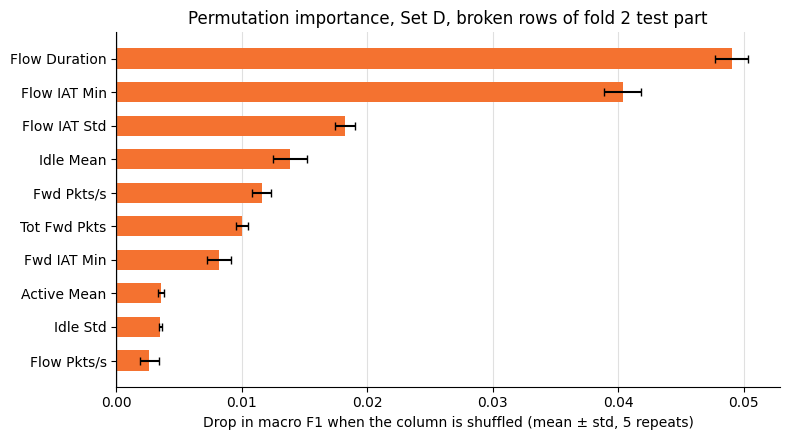

In [10]:
top = pi_table.head(PI_TOP_N).iloc[::-1]   # en önemli en üstte görünsün
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top.index, top['mean_drop'], xerr=top['std'], color=COLOR_BROKEN, height=0.6, capsize=3)
ax.set_xlabel('Drop in macro F1 when the column is shuffled (mean ± std, 5 repeats)')
ax.set_title('Permutation importance, Set D, broken rows of fold ' + str(LAST_FOLD) + ' test part')
ax.axvline(0, color='#5f6368', linewidth=1)
ax.grid(axis='x', color=GRID_COLOR)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

**Comparison with the mutual information list (WP-D1, 7.11, broken subset).** Both views put `Flow Duration` first (MI 0.296) and `Flow IAT Min` near the top (MI 3rd, 0.273), while `Fwd IAT Tot` (MI 11th, 0.143) gets a slightly negative permutation importance here (-0.010: shuffling it did not hurt this model on these rows). MI looks at one column at a time on a 50,000-row sample of all broken rows; permutation importance looks at one fitted model on one fold, so the two lists are not expected to match exactly. The largest drop is about 0.05 in macro F1, so no single timing column carries most of the score on broken rows.

## 10. Binary task: Benign vs attack (plan 10.4)
Sets B and D with `target="label_binary"` (Benign = 0, every attack = 1). The macro F1 is the mean of the two class F1 scores; per-class recall columns and `bot_ddos_confusion` are NaN for this target (WP-0B). Conflicts are removed in the space of the binary label, so fewer rows are removed than in the 5-class runs. Question from the plan: are broken Benign rows also taken for attacks here?

In [11]:
BINARY_SETS = ['B_F_FULL', 'D_F_TIMING']
for name in BINARY_SETS:
    print('=====', name, 'binary')
    pipe = Pipeline([('model', make_model())])
    results['binary_' + name] = run_cv(pipe, df, FEATURE_SETS[name], OUT_CSV,
                                       experiment='binary_' + name[0], sampler='none',
                                       feature_set=name, folds=folds, target='label_binary')

===== B_F_FULL binary
Kat 0


  eğitim: 304870 satır (çelişki atılan: 269 ) | test: 121905 | fit: 0.9 sn
Kat 1


  eğitim: 314395 satır (çelişki atılan: 473 ) | test: 112176 | fit: 0.8 sn
Kat 2


  eğitim: 233667 satır (çelişki atılan: 414 ) | test: 192963 | fit: 0.8 sn


Kat F1'leri: [0.7609 0.8767 0.8121] → 0.8165 ± 0.058
CSV'ye eklendi: ../reports/results_features.csv
===== D_F_TIMING binary
Kat 0


  eğitim: 301235 satır (çelişki atılan: 3904 ) | test: 121905 | fit: 0.6 sn
Kat 1


  eğitim: 309980 satır (çelişki atılan: 4888 ) | test: 112176 | fit: 0.7 sn
Kat 2


  eğitim: 230168 satır (çelişki atılan: 3913 ) | test: 192963 | fit: 0.6 sn


Kat F1'leri: [0.7697 0.8765 0.4798] → 0.7087 ± 0.2053
CSV'ye eklendi: ../reports/results_features.csv


Confusion matrices of the binary task, separately for clean and broken rows (rows = true class, 0 = Benign, 1 = attack).

In [12]:
for name in BINARY_SETS:
    oof = results['binary_' + name][2].to_numpy().astype(int)
    for subset_name, mask in [('clean', ~df['broken'].to_numpy()), ('broken', df['broken'].to_numpy())]:
        cm = pd.crosstab(df['label_binary'].to_numpy()[mask], oof[mask], rownames=['true'], colnames=['pred'])
        share = cm.div(cm.sum(axis=1), axis=0).round(3)
        print(name, subset_name)
        print(share, '\n')

binary_rows = pd.read_csv(OUT_CSV)
print(binary_rows[binary_rows['experiment'].str.startswith('binary')][
    ['experiment', 'feature_set', 'macro_f1_mean', 'macro_f1_std', 'macro_f1_clean', 'macro_f1_broken']].round(3).to_string(index=False))

B_F_FULL clean
pred      0      1
true              
0     0.997  0.003
1     0.362  0.638 

B_F_FULL broken
pred      0      1
true              
0     0.393  0.607
1     0.104  0.896 

D_F_TIMING clean
pred      0      1
true              
0     0.987  0.013
1     0.844  0.156 

D_F_TIMING broken
pred      0      1
true              
0     0.418  0.582
1     0.151  0.849 

experiment feature_set  macro_f1_mean  macro_f1_std  macro_f1_clean  macro_f1_broken
  binary_B    B_F_FULL          0.817         0.058           0.840            0.653
  binary_D  D_F_TIMING          0.709         0.205           0.531            0.640


## 11. Plot: macro F1 per feature set, all / clean / broken (5-class task)
For each set, three bars: all rows, clean subset (Benign/Dos) and broken subset. Each bar is the mean over the 3 grouped folds and the whisker is the std. `run_cv` gives a per-fold std only for all rows, so the per-fold clean and broken F1 are computed here from the same out-of-fold predictions and the same `subset_macro_f1` helper (as in WP-B1). The plot is shown only here, no file is saved.

In [13]:
def subset_f1_per_fold(oof, fold_list, use_broken, labels):
    """OOF tahminlerinden her katın test kısmında, sadece sağlam ya da bozuk satırların macro F1'i."""
    y_true = df['Label'].to_numpy()
    broken = df['broken'].to_numpy()
    pred = np.asarray(oof)
    scores = []
    for train_idx, test_idx in fold_list:
        rows = test_idx[broken[test_idx] == use_broken]
        scores.append(subset_macro_f1(y_true[rows], pred[rows], labels))
    return scores


set_names = list(FEATURE_SETS.keys())
plot_rows = []
for name in set_names:
    row, cm, oof = results[name]
    clean_scores = subset_f1_per_fold(oof, folds, False, CLEAN_CLASSES)
    broken_scores = subset_f1_per_fold(oof, folds, True, CLASSES)
    plot_rows.append({'set': name, 'all_mean': row['macro_f1_mean'], 'all_std': row['macro_f1_std'],
                      'clean_mean': np.mean(clean_scores), 'clean_std': np.std(clean_scores, ddof=1),
                      'broken_mean': np.mean(broken_scores), 'broken_std': np.std(broken_scores, ddof=1)})
plot_table = pd.DataFrame(plot_rows).set_index('set')
print(plot_table.round(3))

                    all_mean  all_std  clean_mean  clean_std  broken_mean  \
set                                                                         
A_FEATS                0.488    0.065       0.741      0.254        0.334   
B_F_FULL               0.499    0.052       0.787      0.222        0.330   
C_TIMING_COLS_24       0.422    0.126       0.622      0.339        0.314   
D_F_TIMING             0.418    0.119       0.612      0.322        0.313   
E_FLOW_DURATION        0.258    0.038       0.579      0.216        0.188   
F_F_TIMING_DERIVED     0.404    0.097       0.567      0.252        0.314   
G_F_TIMING_BROKEN      0.443    0.123       0.617      0.333        0.334   

                    broken_std  
set                             
A_FEATS                  0.071  
B_F_FULL                 0.070  
C_TIMING_COLS_24         0.072  
D_F_TIMING               0.072  
E_FLOW_DURATION          0.028  
F_F_TIMING_DERIVED       0.072  
G_F_TIMING_BROKEN        0.074  


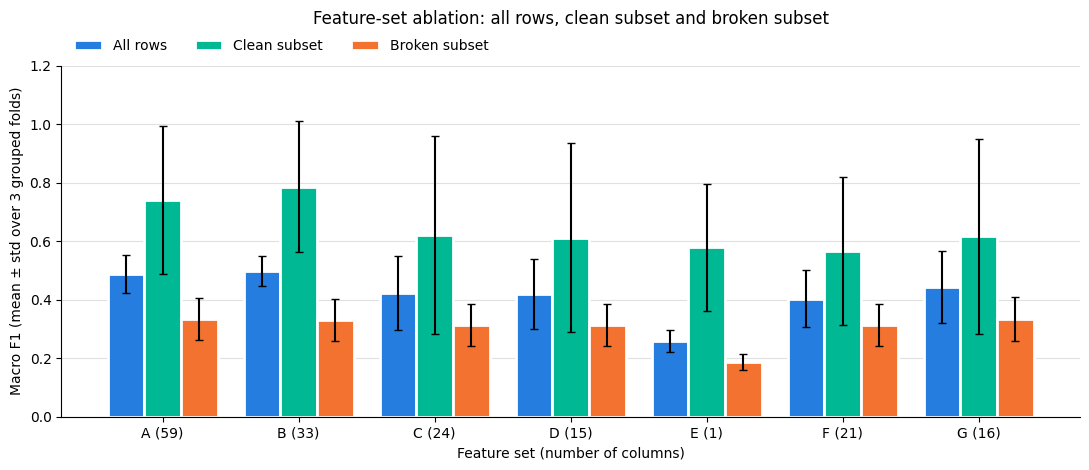

In [14]:
positions = np.arange(len(set_names))
bar_width = 0.27
series = [('all', 'All rows', COLOR_ALL), ('clean', 'Clean subset', COLOR_THIRD), ('broken', 'Broken subset', COLOR_BROKEN)]
fig, ax = plt.subplots(figsize=(11, 4.8))
for offset, (key, label, color) in zip([-bar_width, 0, bar_width], series):
    ax.bar(positions + offset, plot_table[key + '_mean'], bar_width, yerr=plot_table[key + '_std'],
           color=color, edgecolor='white', linewidth=2, capsize=3, label=label)
short_names = []
for name in set_names:
    short_names.append(name[0] + ' (' + str(len(FEATURE_SETS[name])) + ')')
ax.set_xticks(positions)
ax.set_xticklabels(short_names)
ax.set_xlabel('Feature set (number of columns)')
ax.set_ylabel('Macro F1 (mean ± std over 3 grouped folds)')
ax.set_title('Feature-set ablation: all rows, clean subset and broken subset', pad=30)
ax.set_ylim(0, 1.2)   # std çizgileri 1'i geçebiliyor (sağlam alt kümede kat farkı büyük)
ax.grid(axis='y', color=GRID_COLOR)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, ncol=3, loc='lower left', bbox_to_anchor=(0, 1.0))
plt.tight_layout()
plt.show()

## 12. Comment
On grouped CV, the broken-subset macro F1 changed little between feature sets: 0.324 for `F_TIMING` (D), 0.325 for the unpruned `TIMING_COLS` (C), 0.324 with the derived ratios (F) and 0.339-0.342 with the full sets (A, B); only `Flow Duration` alone (E) was clearly lower (0.189). Pruning 24 -> 15 timing columns did not change the scores of the tree model we measured (C vs D), and the six ratio features did not raise the broken-subset score either. Most of the difference between sets comes from the clean subset (Dos recall 0.12 with D vs 0.56 with B), whose per-fold scores vary a lot (std 0.22-0.34). Adding the `broken` flag (G) raised broken-subset F1 from 0.324 to 0.343, so in our measurement `F_TIMING` does not carry all of that information; and in the binary task about 60% of broken Benign rows were predicted as attacks with both B and D.